Постановка задачи

Страховая компания хочет прогнозировать ожидаемые годовые медицинские расходы клиента (annual_medical_cost) на основе множества признаков. Такой прогноз нужен для актуарных расчётов - оценки рисков и обоснованного назначения страховой премии: клиенты с ожидаемо высокими затратами на лечение должны корректно учитываться при ценообразовании полиса. Набор данных включает 100 000 строк и 54 признака. Это задача регрессии, то есть предсказанием модели является непрерывное число.

Названия столбцов с пояснением:
- **person_id** — уникальный ID клиента 
- **age** — возраст клиента
- **sex** — пол (Female, Male, Other)
- **region** — регион проживания (Central, East, North, South, West)
- **urban_rural** — тип местности (Urban, Suburban, Rural)
- **income** — годовой доход
- **education** — уровень образования (No HS, HS, Some College, Bachelors, Masters, Doctorate)
- **marital_status** — семейное положение (Single, Married, Divorced, Widowed)
- **employment_status** — статус занятости (Employed, Self-employed, Unemployed, Retired)
- **household_size** — размер домохозяйства
- **dependents** — число иждивенцев
- **bmi** — индекс массы тела
- **smoker** — статус курения (Never, Former, Current)
- **alcohol_freq** — частота употребления алкоголя (None, Occasional, Weekly, Daily)
- **visits_last_year** — число визитов к врачу за последний год
- **hospitalizations_last_3yrs** — число госпитализаций за 3 года
- **days_hospitalized_last_3yrs** — суммарно дней в стационаре за 3 года
- **medication_count** — число принимаемых препаратов
- **systolic_bp** — систолическое артериальное давление
- **diastolic_bp** — диастолическое артериальное давление
- **ldl** — уровень «плохого» холестерина (ЛПНП)
- **hba1c** — гликированный гемоглобин (маркер диабета)
- **plan_type** — тип плана (HMO, PPO, EPO, POS)
- **network_tier** — уровень покрытия (Bronze, Silver, Gold, Platinum)
- **deductible** — франшиза (сумма, которую клиент платит сам до начала покрытия)
- **copay** — фиксированная доплата за услугу
- **policy_term_years** — срок действия полиса в годах
- **policy_changes_last_2yrs** — число изменений полиса за 2 года
- **provider_quality** — рейтинг качества медицинского провайдера (числовой)
- **risk_score** — скоринговая оценка риска клиента
- **chronic_count** — общее число хронических заболеваний
- **hypertension** — гипертония
- **diabetes** — диабет
- **asthma** — астма
- **copd** — ХОБЛ
- **cardiovascular_disease** — сердечно-сосудистое заболевание
- **cancer_history** — онкология в анамнезе
- **kidney_disease** — болезнь почек
- **liver_disease** — болезнь печени
- **arthritis** — артрит
- **mental_health** — психическое расстройство
- **proc_imaging_count** — число диагностических исследований (визуализация)
- **proc_surgery_count** — число операций
- **proc_physio_count** — число сеансов физиотерапии
- **proc_consult_count** — число консультаций
- **proc_lab_count** — число лабораторных анализов
- **claims_count** — число страховых обращений
- **avg_claim_amount** — средняя сумма по обращению
- **total_claims_paid** — суммарно выплачено по страховым случаям
- **annual_premium** — годовая страховая премия
- **monthly_premium** — месячная страховая премия
- **is_high_risk** — флаг высокого риска (0/1)
- **had_major_procedure** — флаг наличия крупной процедуры (0/1)
- **annual_medical_cost** — годовые медицинские расходы клиента (таргет регрессии)

Импорт основных библиотек

In [135]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [136]:
import numpy as np
import pandas as pd
import seaborn as sns
import phik
import matplotlib.pyplot as plt
import random
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [137]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)


1. Изучение структуры данных

In [138]:
df = pd.read_csv("medical_insurance.csv")
df.head(5)

,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,...,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,0,1,0,2,0,1,1,0,1,0


In [139]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 54 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   sex                          100000 non-null  object 
 3   region                       100000 non-null  object 
 4   urban_rural                  100000 non-null  object 
 5   income                       100000 non-null  float64
 6   education                    100000 non-null  object 
 7   marital_status               100000 non-null  object 
 8   employment_status            100000 non-null  object 
 9   household_size               100000 non-null  int64  
 10  dependents                   100000 non-null  int64  
 11  bmi                          100000 non-null  float64
 12  smoker                       100000 non-null  object 
 13  

Здесь мы видим, что пропуски есть только в столбце alcohol_freq , причем пропусков много. Нужно будет проверить, возможно есть скрытые пропуски. Большинство признаков int или float.

In [140]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_id,100000.0,50000.500000,28867.657797,1.00,25000.7500,50000.5000,75000.2500,100000.00
age,100000.0,47.521500,15.988752,0.00,37.0000,48.0000,58.0000,100.00
income,100000.0,49873.905000,46800.214127,1100.00,21100.0000,36200.0000,62200.0000,1061800.00
household_size,100000.0,2.430900,1.075126,1.00,2.0000,2.0000,3.0000,9.00
dependents,100000.0,0.898380,0.950654,0.00,0.0000,1.0000,1.0000,7.00
bmi,100000.0,26.990512,4.994883,12.00,23.6000,27.0000,30.4000,50.40
visits_last_year,100000.0,1.927650,1.737730,0.00,1.0000,2.0000,3.0000,25.00
hospitalizations_last_3yrs,100000.0,0.093640,0.304848,0.00,0.0000,0.0000,0.0000,3.00
days_hospitalized_last_3yrs,100000.0,0.373350,1.373011,0.00,0.0000,0.0000,0.0000,21.00
medication_count,100000.0,1.236320,1.209358,0.00,0.0000,1.0000,2.0000,11.00


In [141]:
df.describe(include="object").T

,count,unique,top,freq
sex,100000,3,Female,49193
region,100000,5,South,28029
urban_rural,100000,3,Urban,60019
education,100000,6,Bachelors,27996
marital_status,100000,4,Married,53252
employment_status,100000,4,Employed,55269
smoker,100000,3,Never,69709
alcohol_freq,69917,3,Occasional,45078
plan_type,100000,4,PPO,35167
network_tier,100000,4,Silver,40177


2. Проверка на корректность и качество данных

2.1 Проверка на дубликаты

In [142]:
df.duplicated().sum()

np.int64(0)

Дубликаты в датасете отсутствуют

2.2 Проверка на пропуски

In [143]:
df.isnull().sum()

person_id                          0
age                                0
sex                                0
region                             0
urban_rural                        0
income                             0
education                          0
marital_status                     0
employment_status                  0
household_size                     0
dependents                         0
bmi                                0
smoker                             0
alcohol_freq                   30083
visits_last_year                   0
hospitalizations_last_3yrs         0
days_hospitalized_last_3yrs        0
medication_count                   0
systolic_bp                        0
diastolic_bp                       0
ldl                                0
hba1c                              0
plan_type                          0
network_tier                       0
deductible                         0
copay                              0
policy_term_years                  0
p

Явные пропуски есть в alcohol_freq. Возможно есть скрытые пропуски в других признаках

2.3 Корректность по столбцам

In [144]:
#Проверим, что значения числовых признаков корректны. Транспонируем df, чтобы все признаки уместились на экране

df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_id,100000.0,50000.500000,28867.657797,1.00,25000.7500,50000.5000,75000.2500,100000.00
age,100000.0,47.521500,15.988752,0.00,37.0000,48.0000,58.0000,100.00
income,100000.0,49873.905000,46800.214127,1100.00,21100.0000,36200.0000,62200.0000,1061800.00
household_size,100000.0,2.430900,1.075126,1.00,2.0000,2.0000,3.0000,9.00
dependents,100000.0,0.898380,0.950654,0.00,0.0000,1.0000,1.0000,7.00
bmi,100000.0,26.990512,4.994883,12.00,23.6000,27.0000,30.4000,50.40
visits_last_year,100000.0,1.927650,1.737730,0.00,1.0000,2.0000,3.0000,25.00
hospitalizations_last_3yrs,100000.0,0.093640,0.304848,0.00,0.0000,0.0000,0.0000,3.00
days_hospitalized_last_3yrs,100000.0,0.373350,1.373011,0.00,0.0000,0.0000,0.0000,21.00
medication_count,100000.0,1.236320,1.209358,0.00,0.0000,1.0000,2.0000,11.00


В целом числовые признаки выглядят адекватно, нет отрицательных значений, минимальные значения корректны. Да, в некоторых признаках есть выбросы, как и в любых данных, какие-то признаки скошены вправо (mean значительно больше 50%)

In [145]:
#Начнем проверять категориальные признаки
df["sex"].value_counts()

sex
Female    49193
Male      48794
Other      2013
Name: count, dtype: int64

Тут мы видим Other = 2013 , не знаю, что за пол Other, но давайте будем считать, что это нормально, так что не будем считать за пропуск

In [146]:
df["region"].value_counts()

region
South      28029
North      22027
East       19984
West       17879
Central    12081
Name: count, dtype: int64

In [147]:
#Смотреть по одному признаку медленно и неудобно, так что попробуем все сделать через цикл 

cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print("\n\n")
    print(df[col].value_counts(dropna=False))
    




sex
Female    49193
Male      48794
Other      2013
Name: count, dtype: int64



region
South      28029
North      22027
East       19984
West       17879
Central    12081
Name: count, dtype: int64



urban_rural
Urban       60019
Suburban    25021
Rural       14960
Name: count, dtype: int64



education
Bachelors       27996
Some College    25112
HS              24827
Masters         13987
No HS            5120
Doctorate        2958
Name: count, dtype: int64



marital_status
Married     53252
Single      35715
Divorced     6984
Widowed      4049
Name: count, dtype: int64



employment_status
Employed         55269
Retired          19864
Unemployed       12939
Self-employed    11928
Name: count, dtype: int64



smoker
Never      69709
Former     18163
Current    12128
Name: count, dtype: int64



alcohol_freq
Occasional    45078
NaN           30083
Weekly        19833
Daily          5006
Name: count, dtype: int64



plan_type
PPO    35167
HMO    34723
EPO    15121
POS    14989
Nam

Категориальные признаки выглядят адекватно, скрытых пропусков нет 

3. Детальное изучение признаков и таргета

3.1 Числовые признаки 

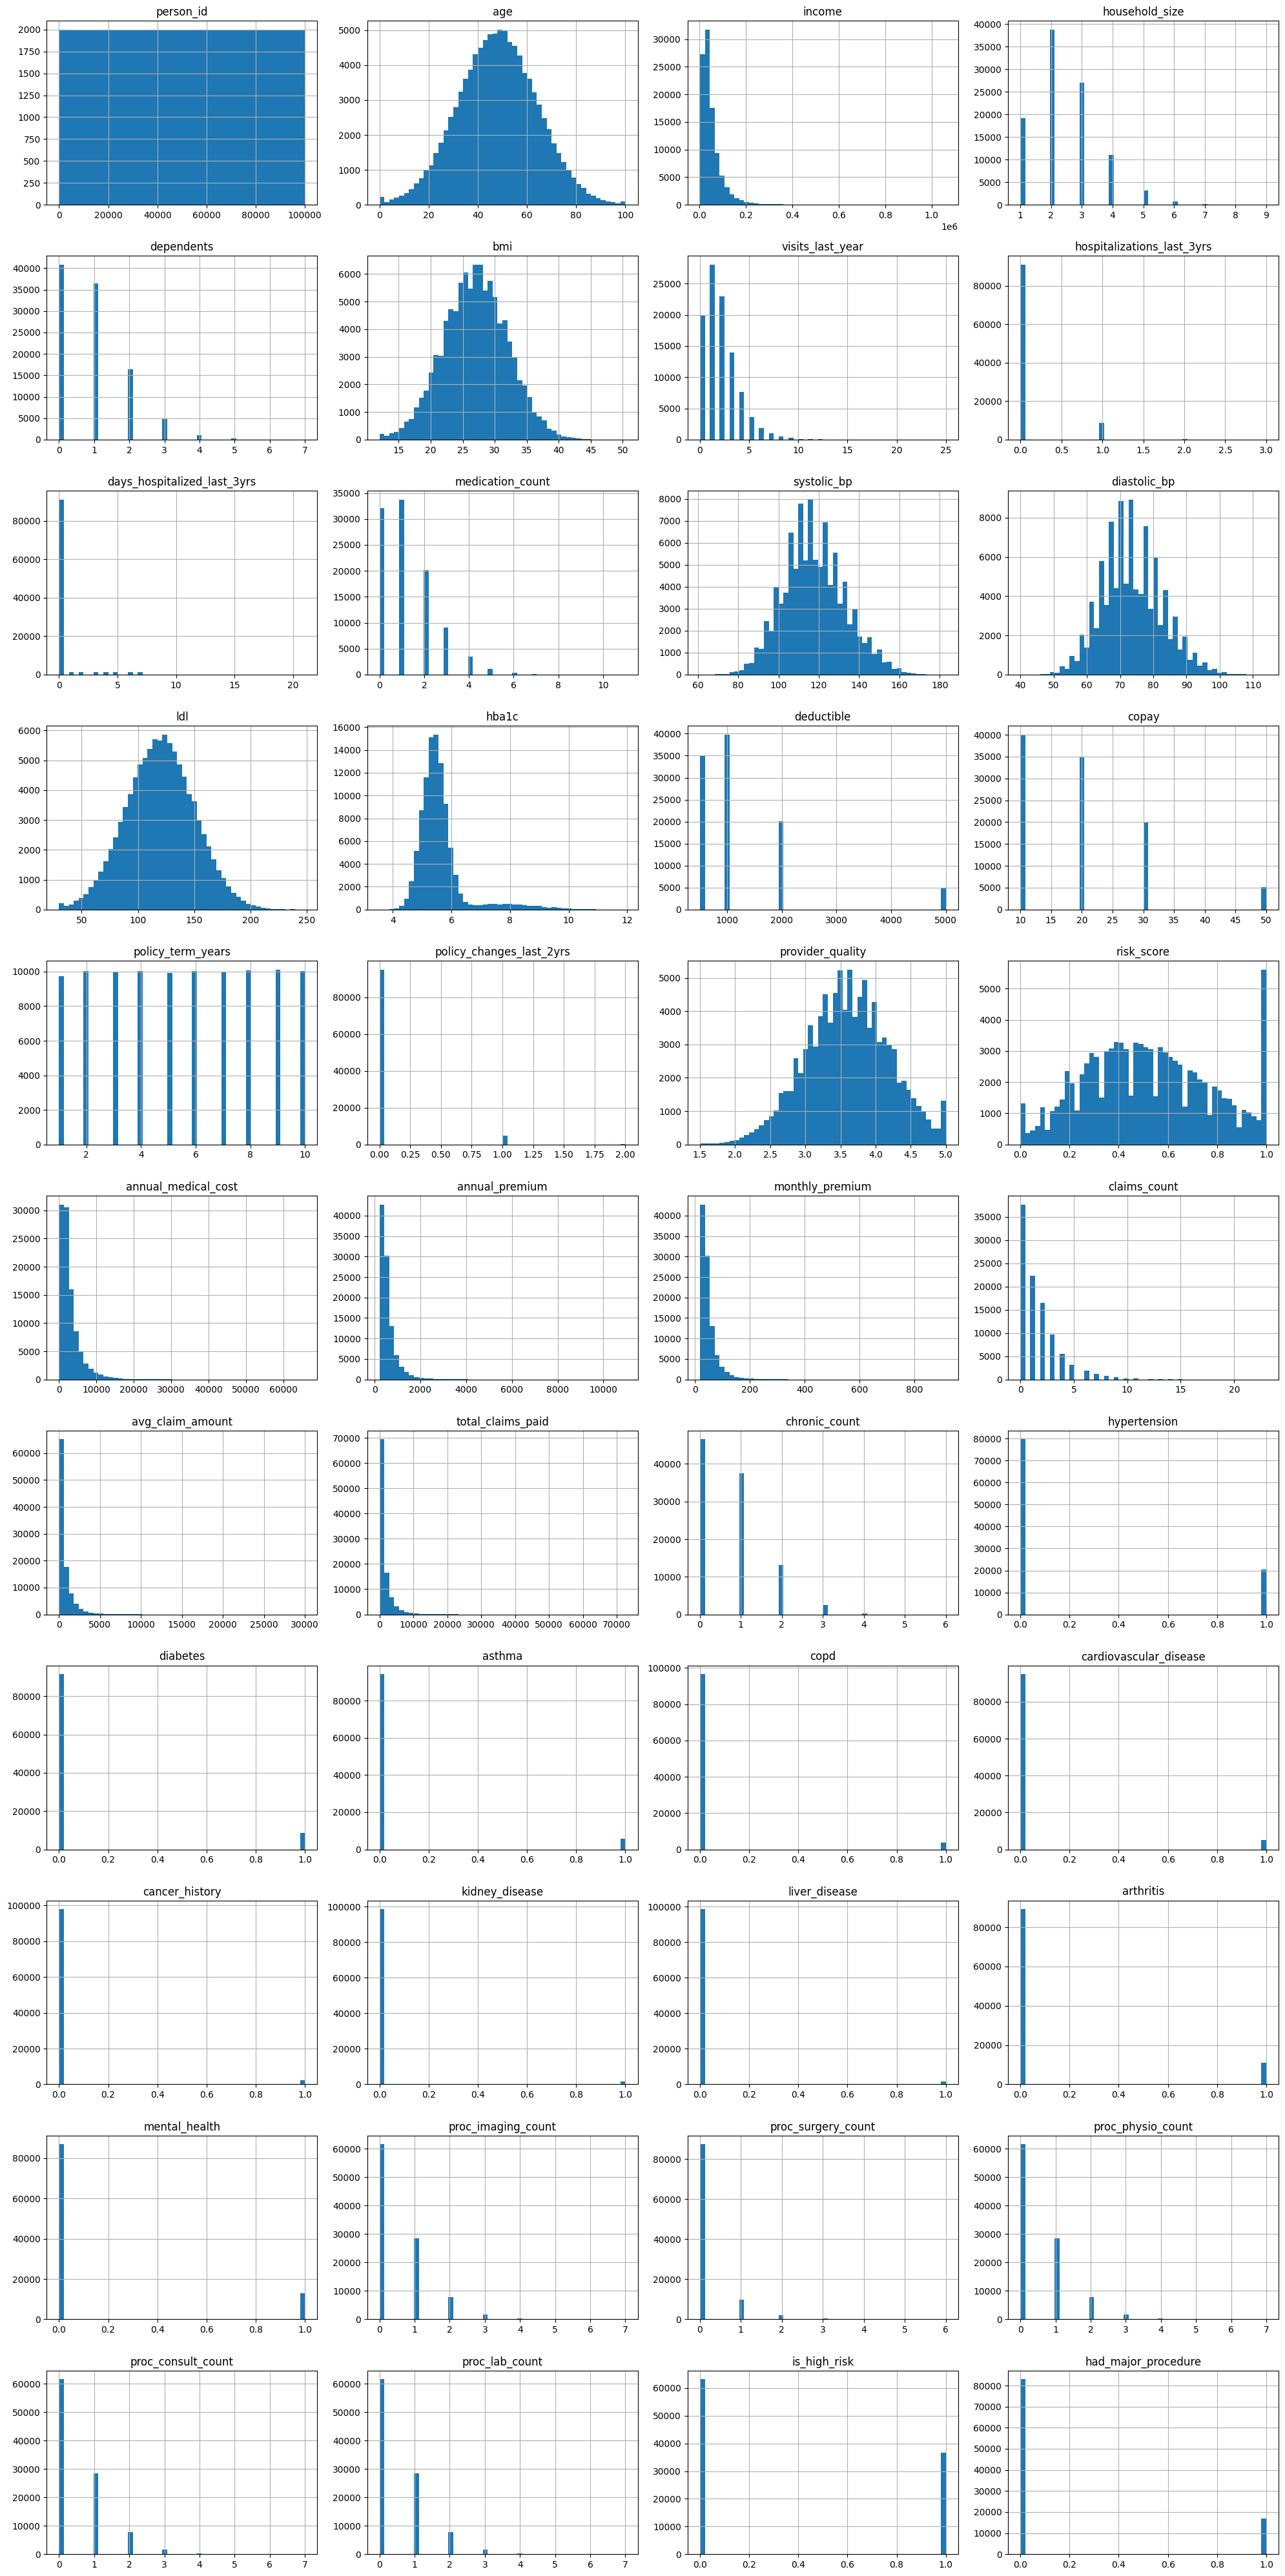

In [148]:
#Не будем смотреть по одному графику, это слишком медленно, посмотрим сразу на все распределения числовых признаков
df.hist(figsize=(20, 40), bins=50, layout=(11, 4))
plt.tight_layout()

Для удобства сгруппируем все признаки, опираясь на графики:

1) Непрерывные, скошенные вправо (mean гораздо больше median) - income, hba1c, annual_medical_cost, annual_premium, monthly_premium, avg_claim_amount, total_claims_paid - это кандидаты на логарифмирование 
2) Непрерывные, нормальное распределение - age, bmi, systolic_bp, diastolic_bp, ldl, provider_quality, risk_score (бОльшая часть значений в самом правом столбике)
3) Дискретные признаки - перечислять не буду, но видно, что во многих признаках большое количество нулей (нули преобладают)
4) Бинарные признаки - нули так же преобладают 

3.2 Категориальные признаки 

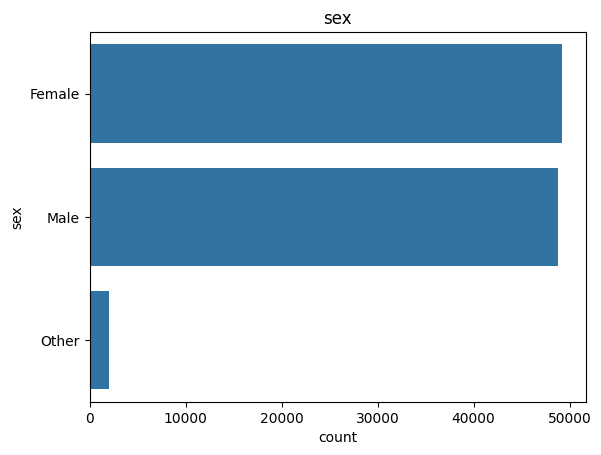

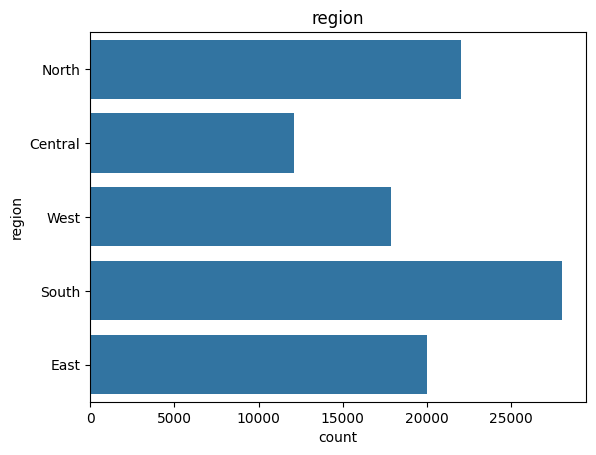

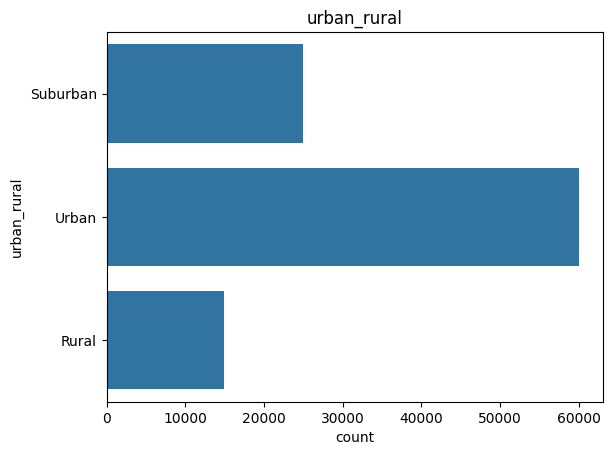

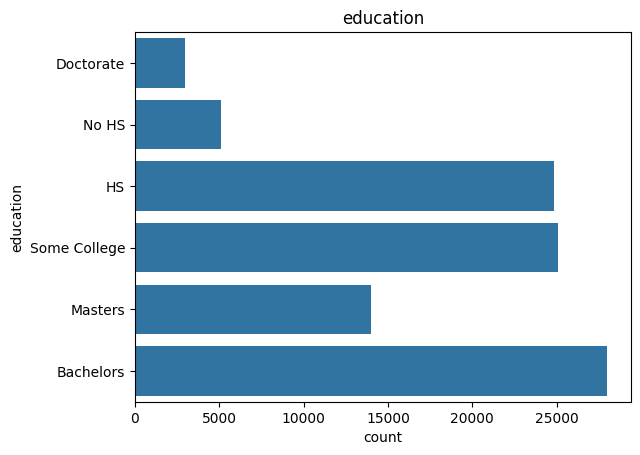

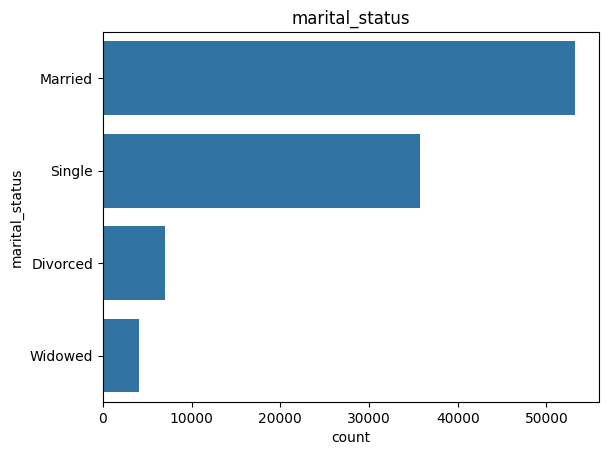

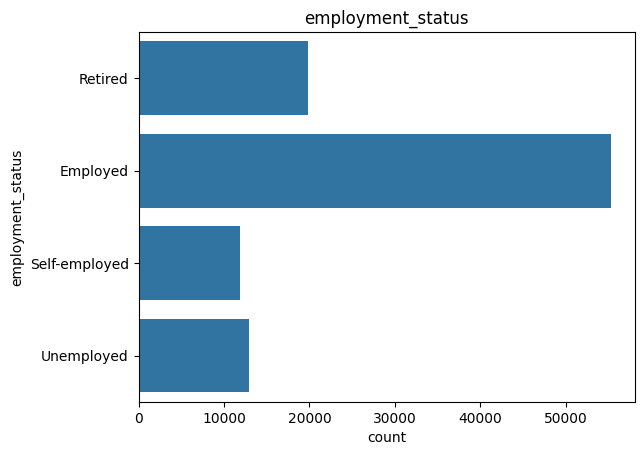

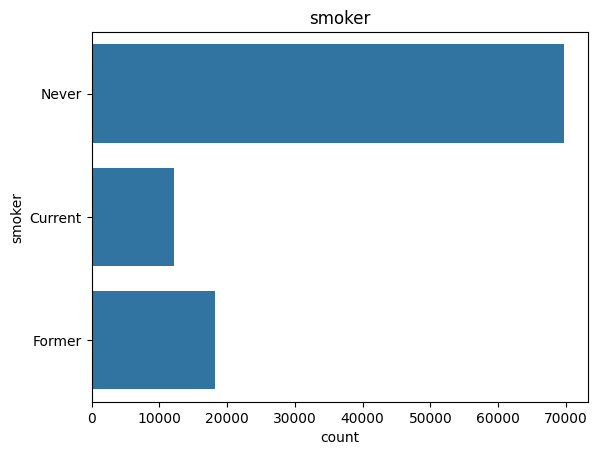

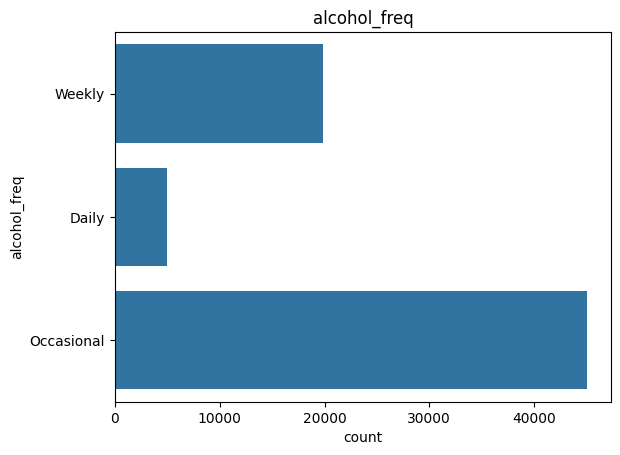

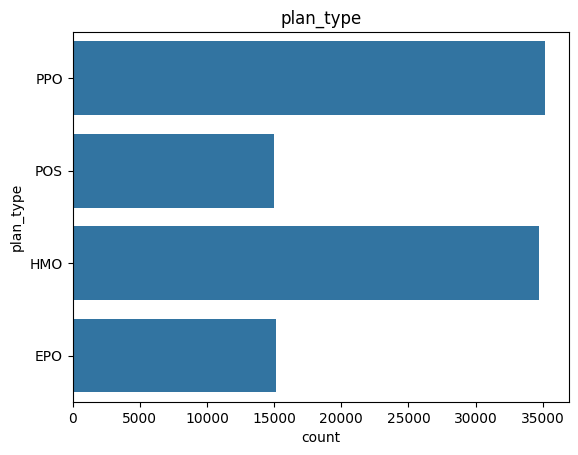

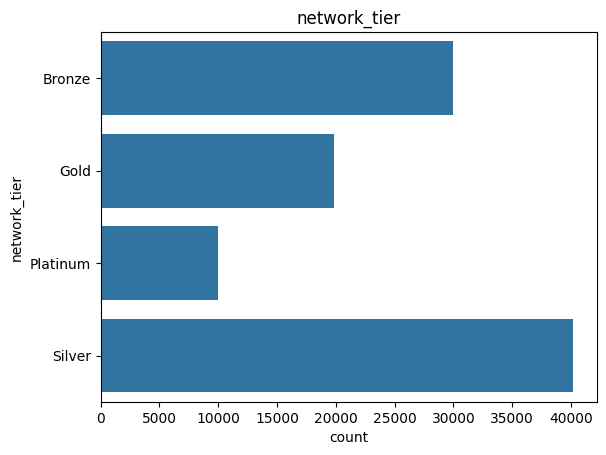

In [149]:
cat_cols = ["sex", "region", "urban_rural", "education", "marital_status", "employment_status", 
            "smoker", "alcohol_freq", "plan_type", "network_tier"]

for col in cat_cols:
    sns.countplot(data=df, y=f"{col}")
    plt.title(col)
    plt.show()


1) sex - мужчин и женщин одинаковое количество, есть еще пол Other 
2) region - больше всего людей с южных и северных регионов 
3) urban_rural - большинство людей приходится на городскую местность 
4) education - очень мало людей с докторской степенью и без школьного образования, большинство людей закончили бакалавриат 
5) marital_status - большинство людей в браке или холостяки 
6) employment - большинство людей работают 
7) smoker - большинство людей никогда не курили 
8) alcohol_freq - большинство людей пьют "только по праздникам"
9) plan_type - большинство людей имеют два тарифа: PPO (самая дорогая страховка) и HMO (самый дешевый вариант)
10) network_tier - у большинства людей уровень покрытия silver и bronze

4. Изучение взаимосвязей между признаками 

4.1 Общая матрица корреляций 

Теперь посмотрим какие признаки коррелируют друг с другом, а также посмотрим связь признаков с таргетом. Сильные корреляции нужно проанализировать отдельно

<Axes: >

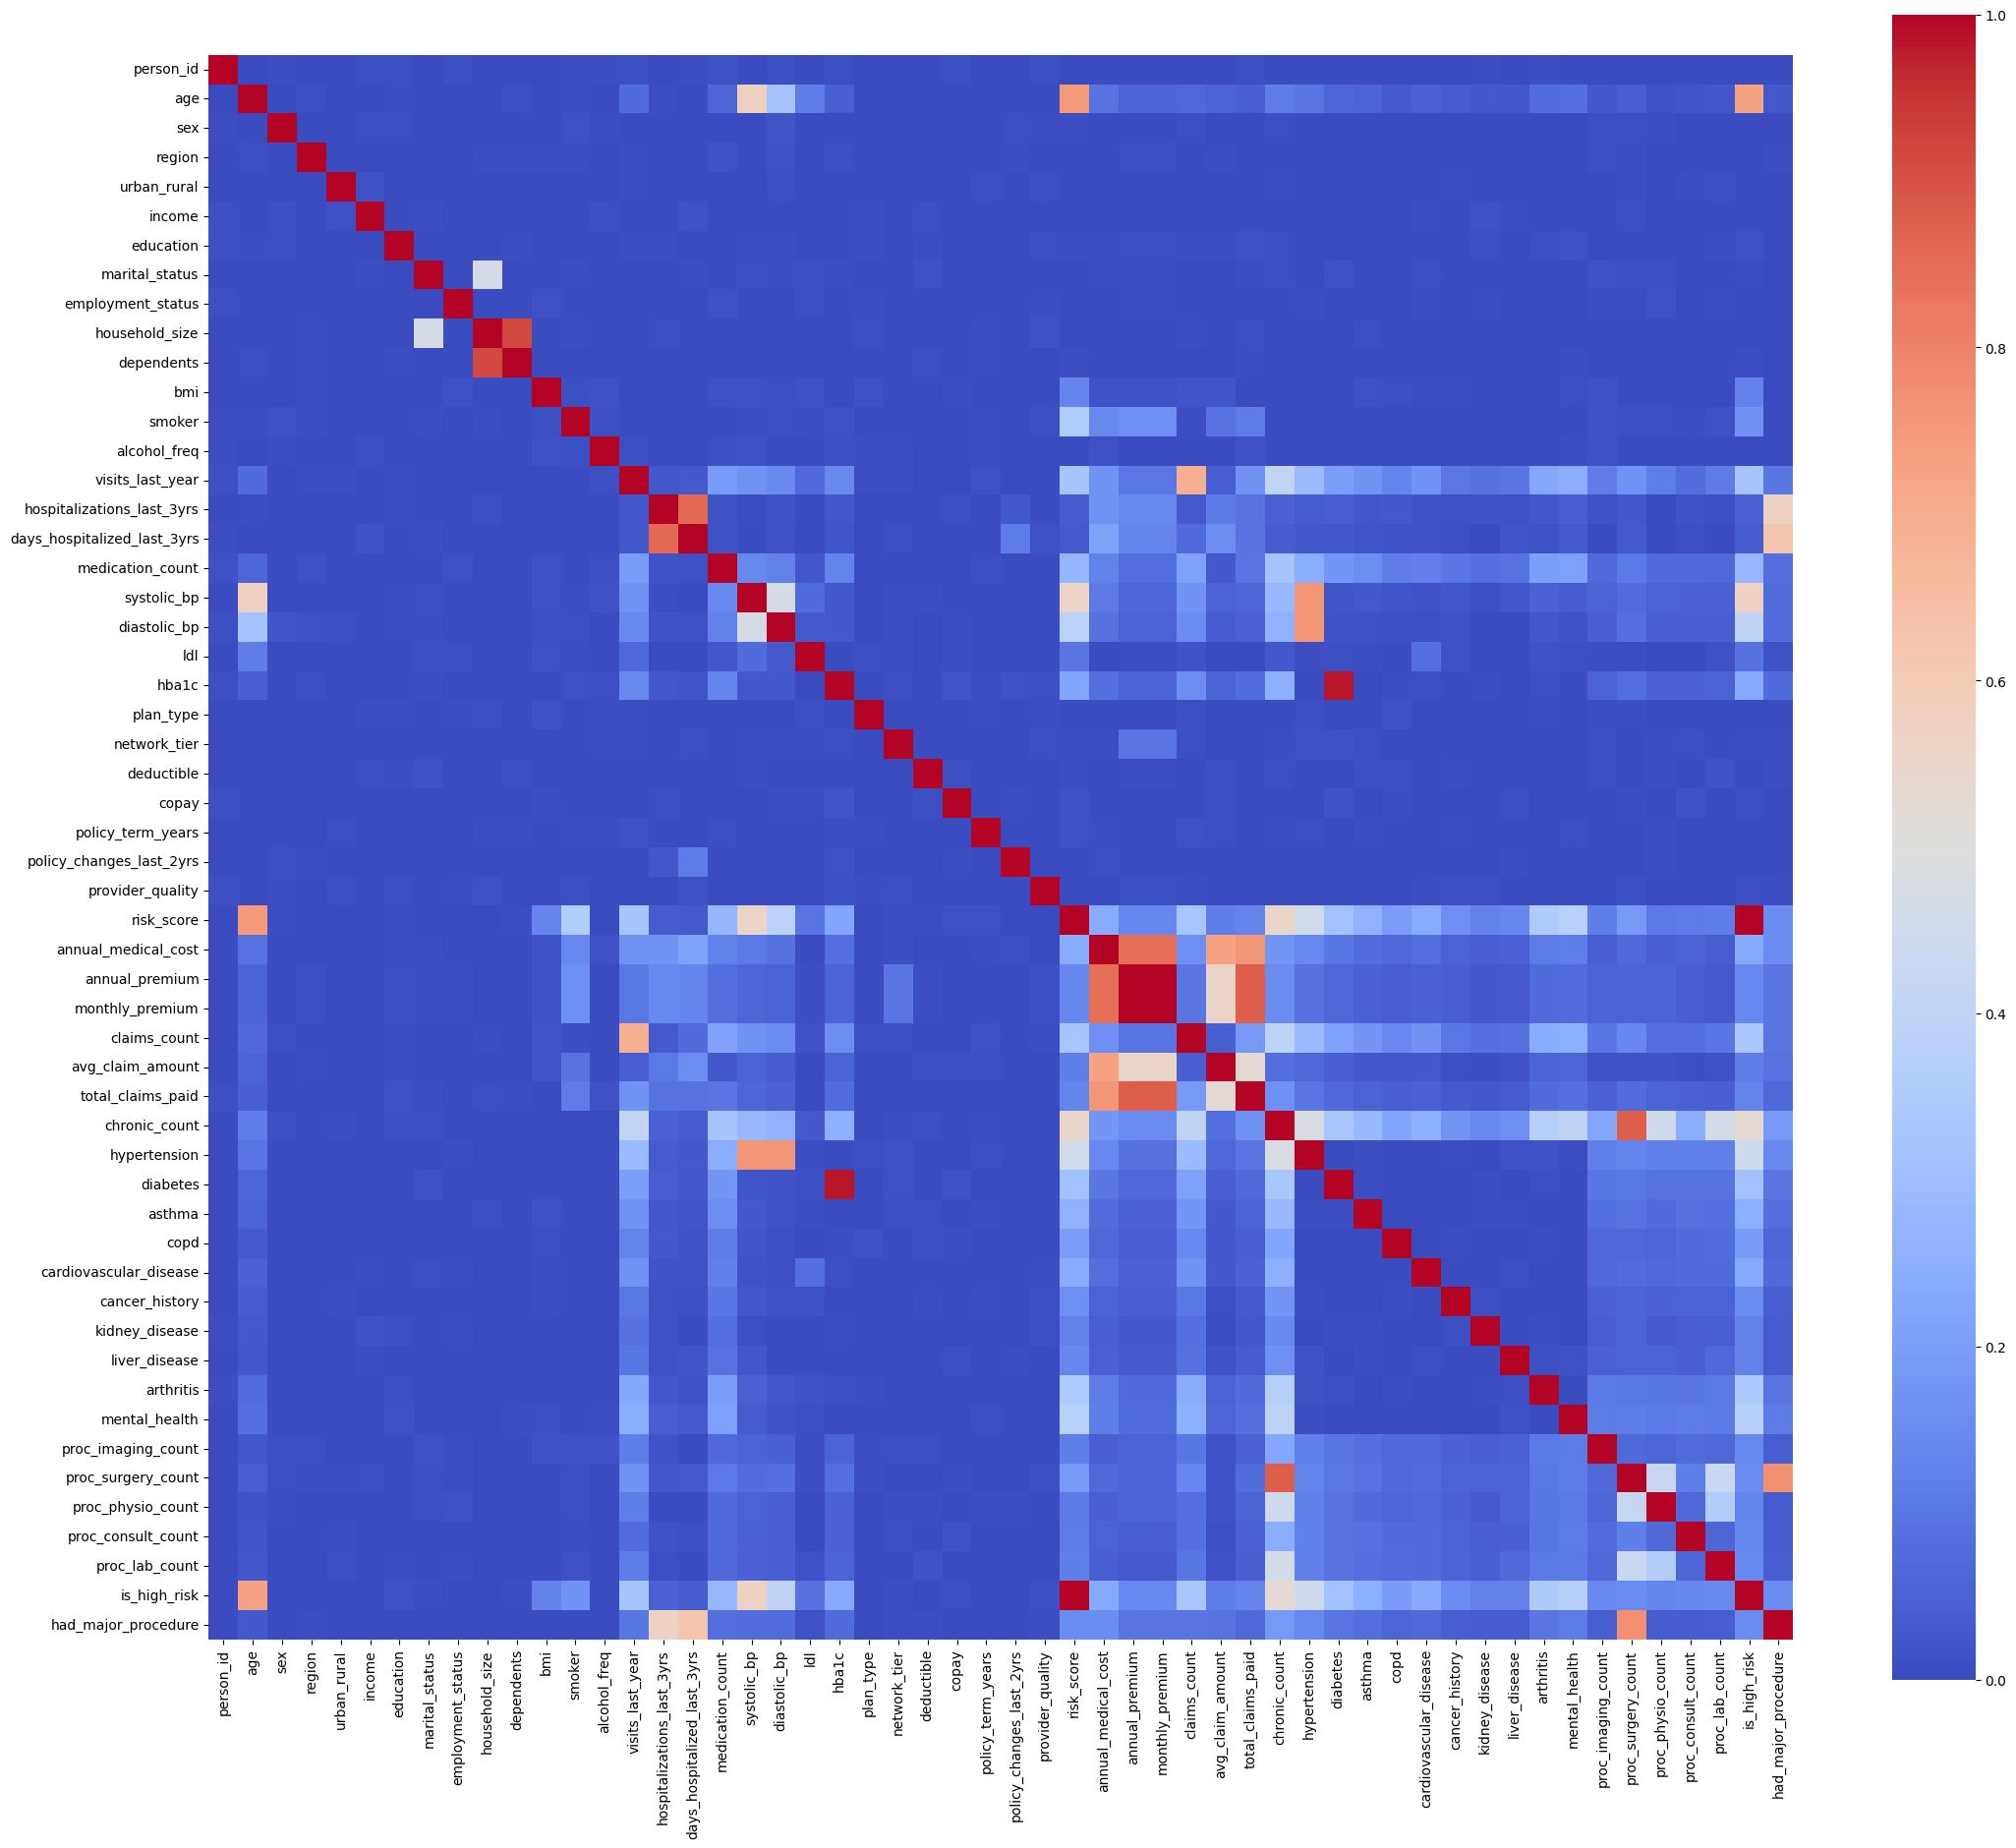

In [150]:
phik_matrix = df.phik_matrix(interval_cols=df.select_dtypes(include="number").columns.tolist())
plt.figure(figsize=(26, 22))
sns.heatmap(phik_matrix, annot=False, fmt=".2f", cmap="coolwarm", xticklabels=True, yticklabels=True, square=True)

Пары, которые стоит проанализировать: 
age vs risk_score
household_size vs dependents
visits_last_year vs claims_count
hospitalizations_last_3yrs vs days_hospitalized_last_3yrs
systolic_bp, diastolic_bp vs hypertension
hbalc vs diabetes 
risk_score vs is_high_risk 
annual_premium vs monthly_premium
annual_premium vs total_claims_paid
annual_premium vs risk_score
chronic_count vs proc_surgery_count

ТАРГЕТ annual_medical_cost vs annual_premium, monthly_premium

4.2 Подробное изучение корреляций между выбранными парами 

<Axes: xlabel='risk_score', ylabel='age'>

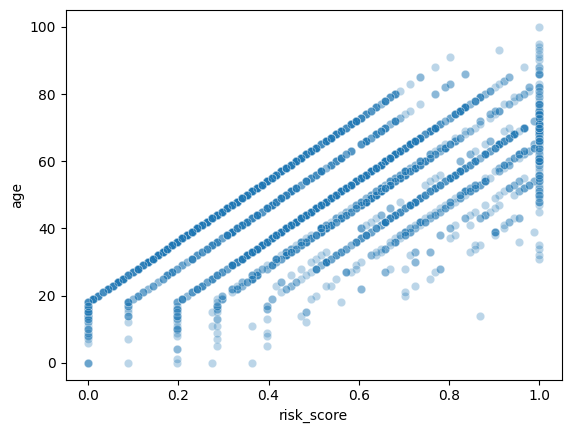

In [151]:
# age vs risk_score
sns.scatterplot(data=df.sample(3000), x="risk_score", y="age", alpha=0.3)

Корреляция между признаками действительно есть, так как на графике видно: молодые люди в основном зафиксированы с маленьким скором риска, а более пожилые люди уже имеют более высокий скор риска 

<Axes: xlabel='household_size', ylabel='dependents'>

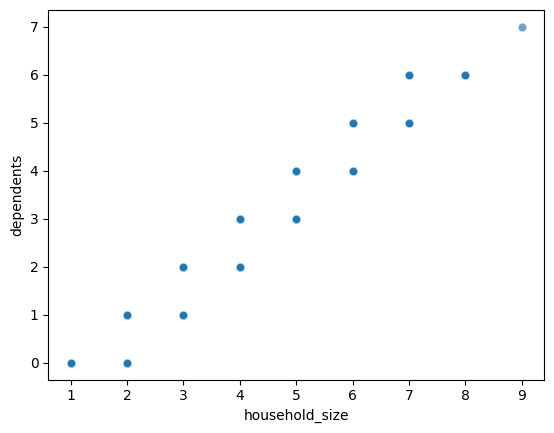

In [152]:
# household_size vs dependents (размер домохозяйства и количество иждивенцов)
sns.scatterplot(data=df, x="household_size", y="dependents", alpha=0.3)

Здесь мы видим четкую линейную связь: чем больше иждивенцов, тем больше размер домохозяйства 

<Axes: xlabel='visits_last_year', ylabel='claims_count'>

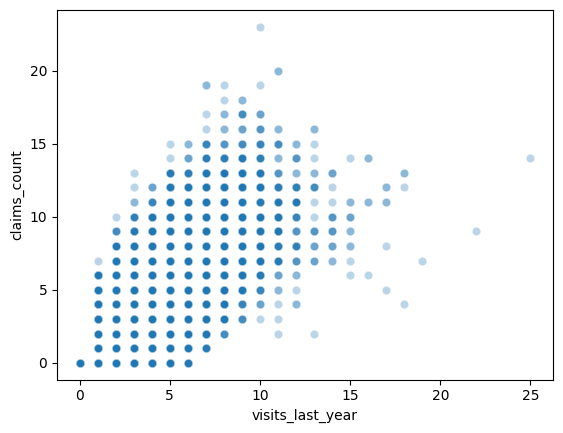

In [153]:
#visits_last_year vs claims_count 
sns.scatterplot(data=df, x="visits_last_year", y="claims_count", alpha=0.3)

В целом данное облако показывает хорошую линейную связь между признаками, что логично, так как чем больше человек посетил мед.учреждение, тем больше у него зачастую жалоб

<Axes: xlabel='hospitalizations_last_3yrs', ylabel='days_hospitalized_last_3yrs'>

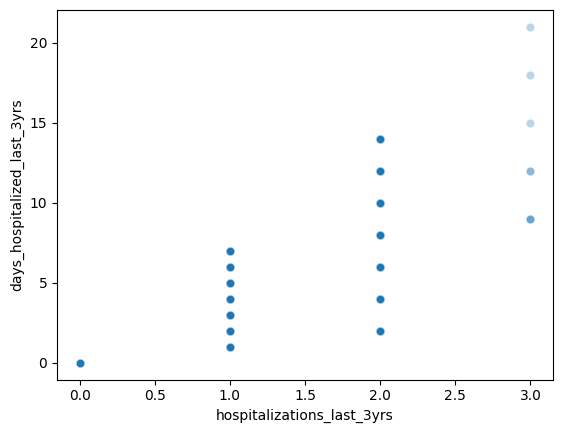

In [154]:
#hospitalizations_last_3yrs vs days_hospitalized_last_3yrs 
sns.scatterplot(data=df, x="hospitalizations_last_3yrs", y="days_hospitalized_last_3yrs", alpha=0.3)

Тут в целом связь логичная, так как чем больше у тебя было госпитализаций за промежуток Х , тем больше дней ты проведешь в мед.учреждении за промежуток Х 

<Axes: xlabel='systolic_bp', ylabel='hypertension'>

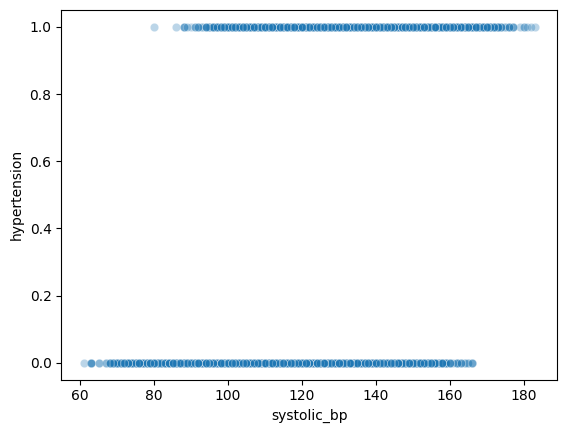

In [155]:
#systolic_bp, diastolic_bp vs hypertension (думаю можно сравнить один параметр, так как они относятся к одному мед. показателю)
sns.scatterplot(data=df, x="systolic_bp", y="hypertension", alpha=0.3)

В целом тут видно, что если у человека давление высокое, то скорее всего у него гипертония, что логично 

<Axes: xlabel='hba1c', ylabel='diabetes'>

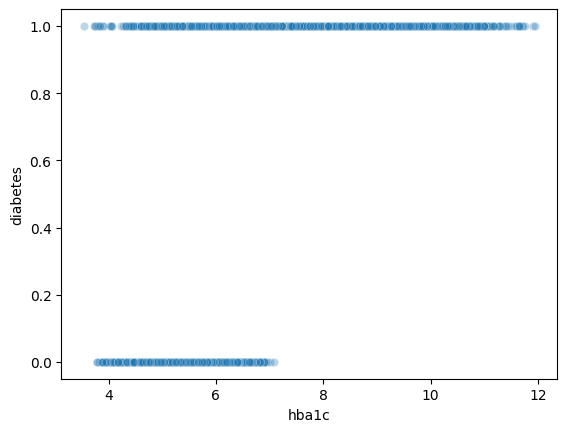

In [156]:
#hbalc vs diabetes 
sns.scatterplot(data=df, x="hba1c", y="diabetes", alpha=0.3)

Тут видно, что данные признаки связанные, хотя и являются разными, диабет есть у людей с высоким и низким hba1c, однако диабет отсутствует у людей, у которых низкий hba1c

<Axes: xlabel='risk_score', ylabel='is_high_risk'>

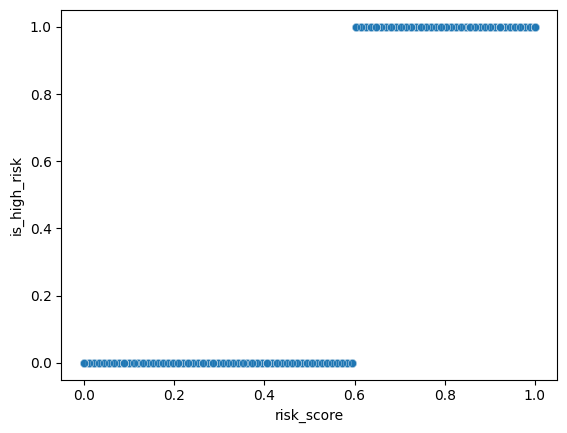

In [157]:
#risk_score vs is_high_risk 
sns.scatterplot(data=df, x="risk_score", y="is_high_risk", alpha=0.3)

Тут так же видно, что данные признаки связаны, флаг риска равен единице только у тех пациентов, у которых скор риска выше 0.6 

<Axes: xlabel='annual_premium', ylabel='monthly_premium'>

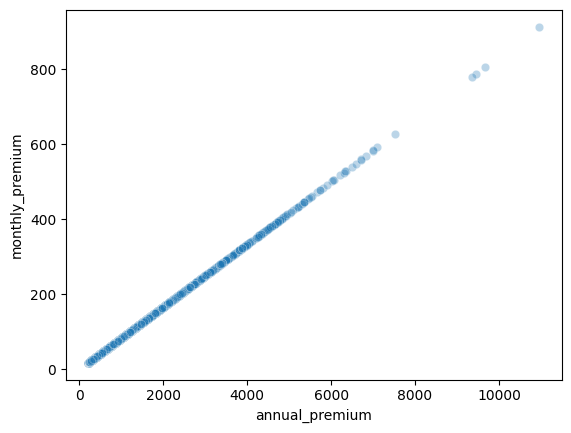

In [158]:
#annual_premium vs monthly_premium
sns.scatterplot(data=df, x="annual_premium", y="monthly_premium", alpha=0.3)

Здесь мы видим идеальную линейную связь, что логично. По всей видимости один признак выведен из другого, что может быть проблемой для линейных моделей

<Axes: xlabel='annual_premium', ylabel='total_claims_paid'>

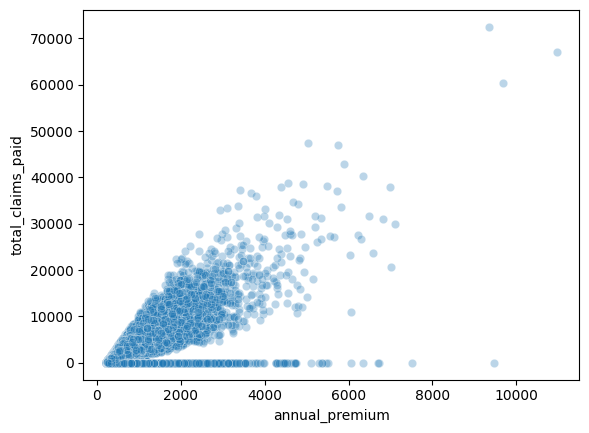

In [159]:
# annual_premium vs total_claims_paid
sns.scatterplot(data=df, x="annual_premium", y="total_claims_paid", alpha=0.3)

Тут видна линейная связь между признаками, по сути чем больше клиент платит за страховку, тем скорее всего он больше потратит, однако на графике видно, что это верно далеко не для всех клиентов. Кто-то платит и ничего по итогу не тратит 

<Axes: xlabel='risk_score', ylabel='annual_premium'>

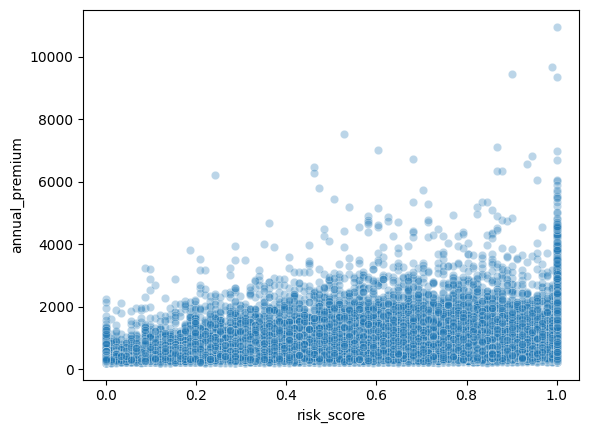

In [160]:
# annual_premium vs risk_score
sns.scatterplot(data=df, x="risk_score", y="annual_premium", alpha=0.3)

Здесь видно, что в основном клиенты с большой страховой премией имеют risk_score = 1 и в целом видно связь роста страховой премии и скора риска

<Axes: xlabel='chronic_count', ylabel='proc_surgery_count'>

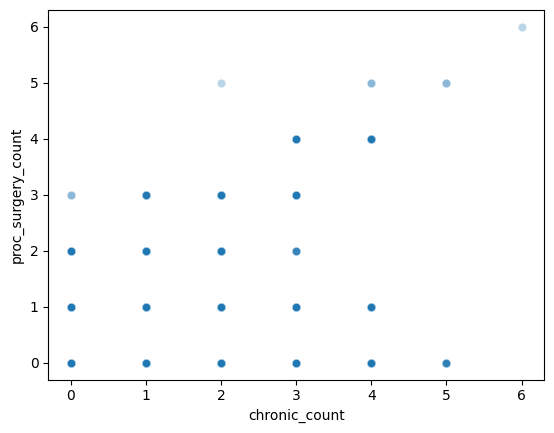

In [161]:
#chronic_count vs proc_surgery_count
sns.scatterplot(data=df, x="chronic_count", y="proc_surgery_count", alpha=0.3)

Тут есть связь: чем больше хронических заболеваний у человека, тем у него будет больше операций 

<Axes: xlabel='annual_medical_cost', ylabel='annual_premium'>

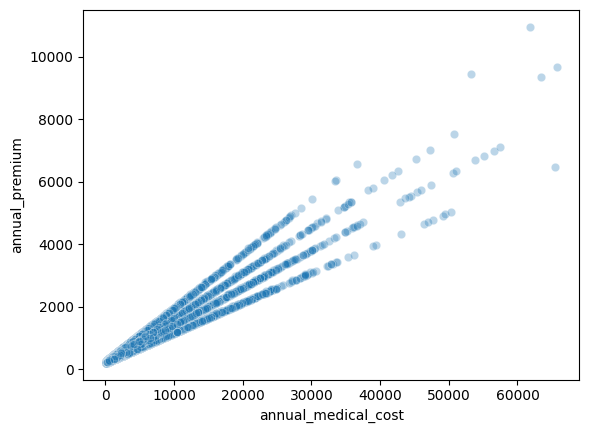

In [162]:
#annual_medical_cost vs annual_premium, monthly_premium
sns.scatterplot(data=df, x="annual_medical_cost", y="annual_premium", alpha=0.3)

<Axes: xlabel='annual_medical_cost', ylabel='monthly_premium'>

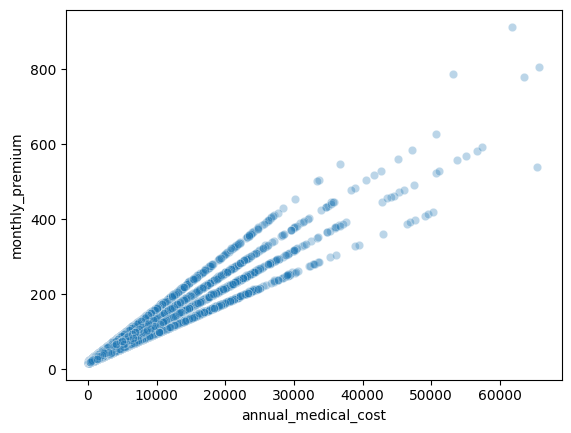

In [163]:
sns.scatterplot(data=df, x="annual_medical_cost", y="monthly_premium", alpha=0.3)

В обоих случаях мы видим почти два одинаковых графика и сильную линейную связь. По сути annual_premium уже содержит в себе информацию о таргете, что является утечкой (так как если модели заранее известен платеж клиента, то и его стоимость рассчитать не составит труда). То же самое касается monthly_premium. У модели при предсказании не должно быть этих данных на руках

5. Препроцессинг данных

5.1 Общие преобразования 

In [164]:
df_preprocessed = df.copy()

In [165]:
#Удаляем признаки, несущие утечки данных (annual_premium, monthly_premium) и не несущий информацию (person_id)

df_preprocessed = df_preprocessed.drop(columns=["person_id", "annual_premium", "monthly_premium"])

In [166]:
# Заменяем пропуски на категорию None (это заполнение константой без fit, поэтому это преобразование идет до сплита)
df_preprocessed["alcohol_freq"] = df_preprocessed["alcohol_freq"].fillna("None")

5.2 Разбиение датасета

In [167]:
X = df_preprocessed.drop(columns=["annual_medical_cost"])
y = df_preprocessed["annual_medical_cost"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

In [168]:
X_train

,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
75220,73,Female,West,Rural,67700.0,Bachelors,Married,Employed,2,0,...,0,0,0,1,0,1,0,1,1,0
48955,43,Female,East,Urban,90200.0,HS,Married,Employed,2,0,...,0,0,0,0,0,0,0,2,0,0
44966,70,Male,North,Rural,64200.0,HS,Married,Employed,2,0,...,0,0,0,2,0,0,0,0,1,0
13568,32,Female,North,Urban,26000.0,Bachelors,Married,Retired,2,0,...,0,0,0,0,0,1,0,0,0,0
92727,33,Male,South,Urban,32100.0,Bachelors,Married,Retired,3,1,...,0,0,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,51,Female,West,Urban,56300.0,HS,Divorced,Unemployed,2,1,...,0,0,0,0,0,0,0,3,1,0
54886,23,Female,South,Suburban,64700.0,Masters,Married,Unemployed,4,2,...,0,0,0,0,2,1,1,1,0,1
76820,60,Male,East,Urban,24100.0,HS,Single,Retired,2,1,...,0,0,0,1,1,0,0,1,1,1
860,61,Male,South,Urban,18600.0,HS,Single,Self-employed,2,1,...,0,0,0,0,0,0,2,0,1,0


In [169]:
X_train_preprocessed = X_train.copy()

In [170]:
X_train_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 80000 entries, 75220 to 15795
Data columns (total 50 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          80000 non-null  int64  
 1   sex                          80000 non-null  object 
 2   region                       80000 non-null  object 
 3   urban_rural                  80000 non-null  object 
 4   income                       80000 non-null  float64
 5   education                    80000 non-null  object 
 6   marital_status               80000 non-null  object 
 7   employment_status            80000 non-null  object 
 8   household_size               80000 non-null  int64  
 9   dependents                   80000 non-null  int64  
 10  bmi                          80000 non-null  float64
 11  smoker                       80000 non-null  object 
 12  alcohol_freq                 80000 non-null  object 
 13  visits_last_year 

In [171]:
numeric_cols = df_preprocessed.select_dtypes(include="number").columns.tolist()
cat_cols = df_preprocessed.select_dtypes(include="object").columns.tolist()

In [172]:
for col in cat_cols:
    print(df_preprocessed.value_counts(f"{col}"))
    print()

sex
Female    49193
Male      48794
Other      2013
Name: count, dtype: int64

region
South      28029
North      22027
East       19984
West       17879
Central    12081
Name: count, dtype: int64

urban_rural
Urban       60019
Suburban    25021
Rural       14960
Name: count, dtype: int64

education
Bachelors       27996
Some College    25112
HS              24827
Masters         13987
No HS            5120
Doctorate        2958
Name: count, dtype: int64

marital_status
Married     53252
Single      35715
Divorced     6984
Widowed      4049
Name: count, dtype: int64

employment_status
Employed         55269
Retired          19864
Unemployed       12939
Self-employed    11928
Name: count, dtype: int64

smoker
Never      69709
Former     18163
Current    12128
Name: count, dtype: int64

alcohol_freq
Occasional    45078
None          30083
Weekly        19833
Daily          5006
Name: count, dtype: int64

plan_type
PPO    35167
HMO    34723
EPO    15121
POS    14989
Name: count, dtype: in

5.4 Кодирование категориальных признаков 

In [173]:
# Onehot для sex, region, urban_rural, marital_status, employment_status, plan_type
onehot_cols = ["sex", "region", "urban_rural", "marital_status", "employment_status", "plan_type"]

for col in onehot_cols:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False) #создание кодировщика
    encoded = ohe.fit_transform(X_train_preprocessed[[col]]) #запоминаем и превращаем столбцы в col 0/1
    cols = ohe.get_feature_names_out([col]) #получаем имена новых столбцов
    encoded = pd.DataFrame(encoded, columns=cols, index=X_train_preprocessed.index) #оборачиаем массив в DataFrame
    X_train_preprocessed = pd.concat([X_train_preprocessed.drop(columns=[col]), encoded], axis=1) #выкидываем старый столбец и приклеиваем новые столбцы



In [174]:
# Ordinal для education, smoker, alcohol_freq, network_tier

ordinal_cols = ["education", "smoker", "alcohol_freq", "network_tier"]

category_orders = [
    ["No HS", "HS", "Some College", "Bachelors", "Masters", "Doctorate"],
    ["Never", "Former", "Current"],
    ["None", "Occasional", "Weekly", "Daily"],
    ["Bronze", "Silver", "Gold", "Platinum"],
]

encoder = OrdinalEncoder(categories=category_orders)
X_train_preprocessed[ordinal_cols] = encoder.fit_transform(X_train_preprocessed[ordinal_cols])


In [175]:
X_train_preprocessed

,age,income,education,household_size,dependents,bmi,smoker,alcohol_freq,visits_last_year,hospitalizations_last_3yrs,...,marital_status_Single,marital_status_Widowed,employment_status_Employed,employment_status_Retired,employment_status_Self-employed,employment_status_Unemployed,plan_type_EPO,plan_type_HMO,plan_type_POS,plan_type_PPO
75220,73,67700.0,3.0,2,0,29.3,1.0,1.0,1,0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
48955,43,90200.0,1.0,2,0,24.1,0.0,0.0,1,0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
44966,70,64200.0,1.0,2,0,36.9,0.0,0.0,2,0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
13568,32,26000.0,3.0,2,0,35.5,1.0,1.0,1,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
92727,33,32100.0,3.0,3,1,32.5,0.0,1.0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,51,56300.0,1.0,2,1,34.6,1.0,0.0,2,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
54886,23,64700.0,4.0,4,2,17.1,0.0,3.0,1,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
76820,60,24100.0,1.0,2,1,27.9,0.0,2.0,0,0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
860,61,18600.0,1.0,2,1,27.8,1.0,1.0,3,0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


5.5 Итоговый пайплан для препроцессинга 

In [176]:
# Список признаков по группам

#Категориальные
cat_cols = X_train.select_dtypes(include="object").columns.tolist()

ord_cols = ["education", "smoker", "alcohol_freq", "network_tier"] # порядковые
onehot_cols = [c for c in cat_cols if c not in ord_cols] # остальные - one hot

#Числовые
num_cols = X_train.select_dtypes(include="number").columns.tolist()

In [177]:
# Теперь все нужно собрать в один ColumnTransformer через мини Pipeline'ы 

ohe_pipe = Pipeline([
    ('ohe', OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

ord_pipe = Pipeline([
    ('ord', OrdinalEncoder(categories=[
        ["No HS", "HS", "Some College", "Bachelors", "Masters", "Doctorate"], #education
        ["Never", "Former", "Current"], #smoker
        ["None", "Occasional", "Weekly", "Daily"], #alcohol_freq
        ["Bronze", "Silver", "Gold", "Platinum"], #network_tier
    ]))
])

preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ohe', ohe_pipe, onehot_cols),
    ('ord', ord_pipe, ord_cols)
])

preprocessor.set_output(transform='pandas')

ColumnTransformer(transformers=[('num', 'passthrough',
                                 ['age', 'income', 'household_size',
                                  'dependents', 'bmi', 'visits_last_year',
                                  'hospitalizations_last_3yrs',
                                  'days_hospitalized_last_3yrs',
                                  'medication_count', 'systolic_bp',
                                  'diastolic_bp', 'ldl', 'hba1c', 'deductible',
                                  'copay', 'policy_term_years',
                                  'policy_changes_last_2yrs',
                                  'provider_quality', 'risk_score',
                                  'clai...
                                 ['sex', 'region', 'urban_rural',
                                  'marital_status', 'employment_status',
                                  'plan_type']),
                                ('ord',
                                 Pipeline(steps=[('ord',
                                                  OrdinalEncoder(categories=[['No '
                                                                              'HS',
                                                                              'HS',
                                                                              'Some '
                                                                              'College',
                                                                              'Bachelors',
                                                                              'Masters',
                                                                              'Doctorate'],
                                                                             ['Never',
                                                                              'Former',
                                                                              'Current'],
                                                                             ['None',
                                                                              'Occasional',
                                                                              'Weekly',
                                                                              'Daily'],
                                                                             ['Bronze',
                                                                              'Silver',
                                                                              'Gold',
                                                                              'Platinum']]))]),
                                 ['education', 'smoker', 'alcohol_freq',
                                  'network_tier'])])

In [178]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_train_preprocessed = pd.DataFrame(X_train_preprocessed, index=X_train.index)

In [179]:
X_train_preprocessed

,num__age,num__income,num__household_size,num__dependents,num__bmi,num__visits_last_year,num__hospitalizations_last_3yrs,num__days_hospitalized_last_3yrs,num__medication_count,num__systolic_bp,...,ohe__employment_status_Self-employed,ohe__employment_status_Unemployed,ohe__plan_type_EPO,ohe__plan_type_HMO,ohe__plan_type_POS,ohe__plan_type_PPO,ord__education,ord__smoker,ord__alcohol_freq,ord__network_tier
75220,73,67700.0,2,0,29.3,1,0,0,0,135.0,...,0.0,0.0,1.0,0.0,0.0,0.0,3.0,1.0,1.0,3.0
48955,43,90200.0,2,0,24.1,1,0,0,0,120.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
44966,70,64200.0,2,0,36.9,2,0,0,2,116.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
13568,32,26000.0,2,0,35.5,1,0,0,0,114.0,...,0.0,0.0,0.0,1.0,0.0,0.0,3.0,1.0,1.0,2.0
92727,33,32100.0,3,1,32.5,0,0,0,1,113.0,...,0.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,51,56300.0,2,1,34.6,2,0,0,0,139.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0
54886,23,64700.0,4,2,17.1,1,0,0,0,140.0,...,0.0,1.0,0.0,1.0,0.0,0.0,4.0,0.0,3.0,3.0
76820,60,24100.0,2,1,27.9,0,0,0,1,125.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,2.0
860,61,18600.0,2,1,27.8,3,0,0,2,116.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0
